### Testing the Elliptical Approach vs. the Taylor (frozen-turbulence) model

In [1]:
import flap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import correlate
from scipy.optimize import curve_fit
from poloidal_flow.analysis import parabolic_func
from poloidal_flow import CorrelationConfig, CorrelationAnalysis, ABESConfig, ABESDataReader
from scipy.interpolate import CubicSpline
from scipy.optimize import fsolve

defl0 = flap.load('../pickled_shot_data/20250409.046_highpass_500_defl0.pkl')
defl1 = flap.load('../pickled_shot_data/20250409.046_highpass_500_defl1.pkl')

s = 37.909116 # mm

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [16]:
t = 4
ch = 15
twindow = 1

dev_r = ABESDataReader(
    ABESConfig('20250409.046', True)
).read_spatial_calibration()

defl0_time_slice = defl0.slice_data(
    slicing = {'Time': flap.Intervals(t - twindow/2, t + twindow/2), 'Channel number': ch},
)

defl1_time_slice = defl1.slice_data(
    slicing = {'Time': flap.Intervals(t - twindow/2, t + twindow/2), 'Channel number': ch},
)

# Interleaved chopper grids, closes value slicing can leave defl0
# and defl1 differing by 1 sample. Truncate to the common length.
time_dim_0 = defl0_time_slice.get_coordinate_object('Time').dimension_list[0]
time_dim_1 = defl1_time_slice.get_coordinate_object('Time').dimension_list[0]
n = min(defl0_time_slice.data.shape[time_dim_0],
        defl1_time_slice.data.shape[time_dim_1])

sl0 = [slice(None)] * defl0_time_slice.data.ndim
sl0[time_dim_0] = slice(0, n)
defl0_time_slice.data = defl0_time_slice.data[tuple(sl0)]
defl0_time_slice.shape = defl0_time_slice.data.shape

sl1 = [slice(None)] * defl1_time_slice.data.ndim
sl1[time_dim_1] = slice(0, n)
defl1_time_slice.data = defl1_time_slice.data[tuple(sl1)]
defl1_time_slice.shape = defl1_time_slice.data.shape

In [17]:
anal = CorrelationAnalysis(
    defl0, defl1,
    CorrelationConfig('parabola', 1, xcorr_interval = 100)
)

In [18]:
acf0 = anal.acf_window_single(defl0_time_slice)
acf1 = anal.acf_window_single(defl1_time_slice)
ccf = anal.ccf_window_single(defl1_time_slice, defl0_time_slice)

acfmean = (acf0.data + acf1.data) / 2

In [19]:
deltat, corr, popt = anal.fit_parabola(ccf)
print(f'delta t = {deltat} us, CCF max = {corr}')

# 5-sample window that fit_parabola fits, in us
ind_max = np.argmax(np.abs(ccf.data))
fit_lags = ccf.coordinate('Time lag')[0][ind_max-2:ind_max+3] * 1e6


delta t = 6.2+/-2.0 us, CCF max = 0.469+/-0.031


Def. szerint $\tau_0$ az a time lag ahol $CCF(\tau_{max}) = ACF(\tau_0)$

In [20]:
acf_interp = CubicSpline(acf0.coordinate('Time lag')[0], acfmean)

tau_dense = np.linspace(-100e-6, 100e-6, 1000)
tau0 = fsolve(lambda x: acf_interp(x) - corr.nominal_value, x0 = 20e-6)[0] * 1e6

print(f'tau0 = {tau0} us')


tau0 = 17.72902029761364 us


In [21]:
v = s*deltat / (deltat**2 + tau0**2)
v

0.6662214495577911+/-0.16770319697898436

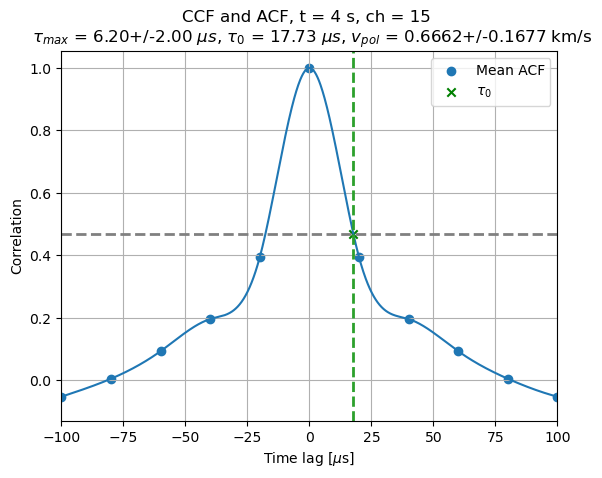

In [22]:
plt.title(f'CCF and ACF, t = {t} s, ch = {ch} \n $\\tau_{{max}}$ = {deltat:.2f} $\\mu s$, $\\tau_{0}$ = {tau0:.2f} $\\mu s$, $v_{{pol}}$ = {v:.4f} km/s')
plt.xlabel('Time lag [$\\mu$s]')
plt.ylabel('Correlation')

plt.scatter(acf0.coordinate('Time lag')[0] * 1e6, acfmean, label = 'Mean ACF')
plt.plot(tau_dense * 1e6, acf_interp(tau_dense))
plt.scatter(tau0, corr.nominal_value, marker = 'x', label = '$\\tau_0$', c = 'g')
plt.axhline(corr.nominal_value, ls = '--', c = 'grey', lw = 2)

plt.axvline(tau0, c = 'tab:green', ls = '--', lw = 2)

plt.legend()

plt.xlim(-100, 100)

plt.grid()
plt.savefig('acf_fit.pdf')

In [28]:
print(dev_r[ch])

6.216160969149997


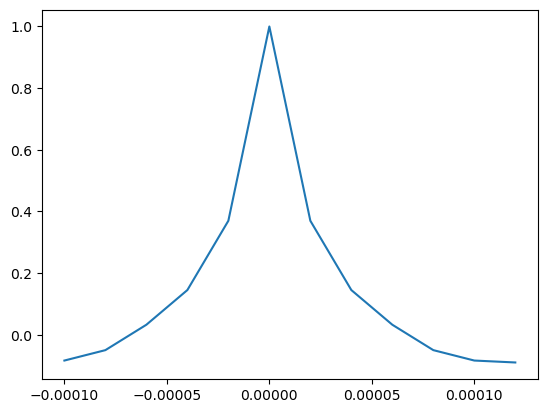

In [29]:
plt.plot(acf0.coordinate('Time lag')[0], acf0.data)